In [1]:
import pandas as pd

from sklearn.datasets import load_breast_cancer

# 1. Cargar el objeto dataset
cancer = load_breast_cancer()

# 2. Convertir a DataFrame (para visualizar)
df_cancer = pd.DataFrame(cancer['data'], columns=cancer['feature_names'])
df_cancer['target'] = cancer['target'] # 0=Maligno, 1=Benigno

print(df_cancer.head())
print(f"\nDimensiones: {df_cancer.shape}")

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [2]:
print(df_cancer.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

# 1. Definir X e y
X = df_cancer.drop('target', axis=1)
y = df_cancer['target']

# 2. Split y Escalado
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# 3. Entrenar SVM Lineal
model_linear = SVC(kernel='linear')
model_linear.fit(X_train_s, y_train)

# 4. Entrenar SVM RBF
model_rbf = SVC(kernel='rbf', C=1, gamma="auto") # Por defecto usa kernel='rbf'
model_rbf.fit(X_train_s, y_train)

# 5. Entrenar SVM Poly
model_poly = SVC(kernel='poly', degree=3)
model_poly.fit(X_train_s, y_train)

print("Modelos SVM entrenados.")

Modelos SVM entrenados.


In [14]:
from sklearn.metrics import confusion_matrix, classification_report

pred_linear = model_linear.predict(X_test_s)
pred_rbf = model_rbf.predict(X_test_s)
pred_poly = model_poly.predict(X_test_s)

print("SVM Lineal:")
print(confusion_matrix(y_test, pred_linear))
print(classification_report(y_test, pred_linear))

print("SVM RBF:")
print(confusion_matrix(y_test, pred_rbf))
print(classification_report(y_test, pred_rbf))

print("SVM Poly:")
print(confusion_matrix(y_test, pred_poly))
print(classification_report(y_test, pred_poly))

SVM Lineal:
[[ 64   2]
 [  2 103]]
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        66
           1       0.98      0.98      0.98       105

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171

SVM RBF:
[[ 64   2]
 [  1 104]]
              precision    recall  f1-score   support

           0       0.98      0.97      0.98        66
           1       0.98      0.99      0.99       105

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171

SVM Poly:
[[ 48  18]
 [  0 105]]
              precision    recall  f1-score   support

           0       1.00      0.73      0.84        66
           1       0.85      1.00      0.92       105

    accuracy                           0.89       171
   macro avg       0.93     

              precision    recall  f1-score   support

           0       0.98      0.97      0.98        66
           1       0.98      0.99      0.99       105

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171



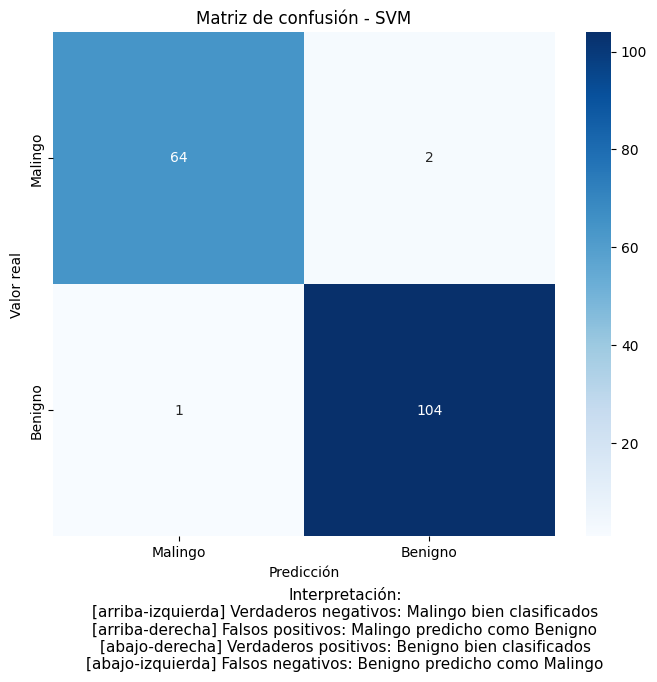

In [15]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Matriz de confusión
cm = confusion_matrix(y_test, pred_rbf)

# Mostrar reporte de clasificación
print(classification_report(y_test, pred_rbf))

# Visualizar matriz de confusión
plt.figure(figsize=(7,6))
ax = sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Malingo', 'Benigno'],
    yticklabels=['Malingo', 'Benigno']
)
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title('Matriz de confusión - SVM')

plt.tight_layout()

# Interpretación debajo del gráfico
plt.figtext(
    0.5, -0.12,
    "Interpretación:\n"
    "[arriba-izquierda] Verdaderos negativos: Malingo bien clasificados\n"
    "[arriba-derecha] Falsos positivos: Malingo predicho como Benigno\n"
    "[abajo-derecha] Verdaderos positivos: Benigno bien clasificados\n"
    "[abajo-izquierda] Falsos negativos: Benigno predicho como Malingo",
    wrap=True, ha='center', fontsize=11
)

plt.show()

              precision    recall  f1-score   support

           0       0.97      0.97      0.97        66
           1       0.98      0.98      0.98       105

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171



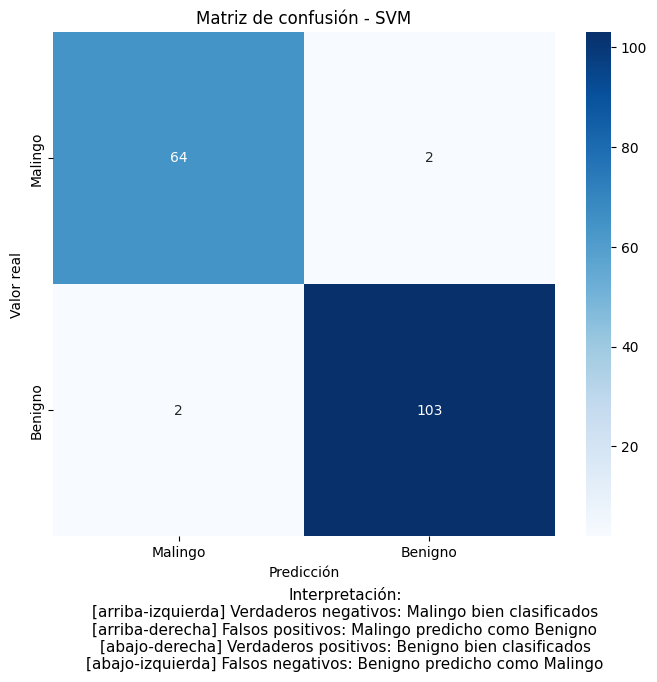

In [7]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Matriz de confusión
cm = confusion_matrix(y_test, pred_linear)

# Mostrar reporte de clasificación
print(classification_report(y_test, pred_linear))

# Visualizar matriz de confusión
plt.figure(figsize=(7,6))
ax = sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Malingo', 'Benigno'],
    yticklabels=['Malingo', 'Benigno']
)
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title('Matriz de confusión - SVM')

plt.tight_layout()

# Interpretación debajo del gráfico
plt.figtext(
    0.5, -0.12,
    "Interpretación:\n"
    "[arriba-izquierda] Verdaderos negativos: Malingo bien clasificados\n"
    "[arriba-derecha] Falsos positivos: Malingo predicho como Benigno\n"
    "[abajo-derecha] Verdaderos positivos: Benigno bien clasificados\n"
    "[abajo-izquierda] Falsos negativos: Benigno predicho como Malingo",
    wrap=True, ha='center', fontsize=11
)

plt.show()

In [8]:
from sklearn.model_selection import GridSearchCV

# Definir la rejilla de parámetros
param_grid = {'C': [0.1, 1, 10, 100], 'gamma': [1, 0.1, 0.01, 0.001]}

# Buscar la mejor combinación
grid = GridSearchCV(SVC(), param_grid, refit=True, verbose=2)
grid.fit(X_train_s, y_train)

print(f"Mejores parámetros: {grid.best_params_}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
[CV] END .....................................C=0.1, gamma=1; total time=   0.0s
[CV] END .....................................C=0.1, gamma=1; total time=   0.0s
[CV] END .....................................C=0.1, gamma=1; total time=   0.0s
[CV] END .....................................C=0.1, gamma=1; total time=   0.0s
[CV] END .....................................C=0.1, gamma=1; total time=   0.0s
[CV] END ...................................C=0.1, gamma=0.1; total time=   0.0s
[CV] END ...................................C=0.1, gamma=0.1; total time=   0.0s
[CV] END ...................................C=0.1, gamma=0.1; total time=   0.0s
[CV] END ...................................C=0.1, gamma=0.1; total time=   0.0s
[CV] END ...................................C=0.1, gamma=0.1; total time=   0.0s
[CV] END ..................................C=0.1, gamma=0.01; total time=   0.0s
[CV] END ..................................C=0.1